<a href="https://colab.research.google.com/github/Ahmed-Rafi07/-MongoDB-connection-string-in-the-.env-file-/blob/main/Multivariate_Outlier_Detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

```markdown
# GlobalMart Portfolio & Pricing Analysis: Relationship Structures & Segmentation

This notebook contains the complete multivariate visualization pipeline to audit relationship structures across and within our customer segments.
```

In [10]:
import numpy as np
import pandas as pd

# Generate a mock 'globalmart_sales.csv' file to let the pipeline execute successfully
np.random.seed(42)
n_samples = 2500

sales = np.random.exponential(scale=250, size=n_samples) + 10
quantity = np.random.randint(1, 10, size=n_samples)
discount = np.random.choice([0.0, 0.1, 0.2, 0.4, 0.6, 0.8], size=n_samples, p=[0.4, 0.1, 0.1, 0.1, 0.1, 0.2])

# Calculate a realistic mock profit where discounts severely penalize furniture margins
base_margin = 0.15
profit = sales * (base_margin - discount * 0.8) + np.random.normal(0, 15, size=n_samples)
category = np.random.choice(['Furniture', 'Office Supplies', 'Technology'], size=n_samples, p=[0.3, 0.4, 0.3])

mock_df = pd.DataFrame({
    'Sales': sales,
    'Profit': profit,
    'Quantity': quantity,
    'Discount': discount,
    'Category': category
})

mock_df.to_csv('globalmart_sales.csv', index=False)
print("Generated mock 'globalmart_sales.csv' file successfully!")

Generated mock 'globalmart_sales.csv' file successfully!


```markdown
## Subtask 1: Establish the Cluster Baseline
We load the data, engineer the derived features (`profit_margin`, `revenue_per_unit`), scale the numerical columns, and apply K-Means clustering ($K=4$) to attach the cluster labels.
```

In [11]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

# Load the freshly generated dataset
df = pd.read_csv('globalmart_sales.csv')

# Recreate derived features
df['profit_margin'] = df['Profit'] / df['Sales']
df['revenue_per_unit'] = df['Sales'] / df['Quantity']

# Handle potential division by zero/NaNs
df['profit_margin'] = df['profit_margin'].fillna(0)
df['revenue_per_unit'] = df['revenue_per_unit'].fillna(0)

# Features for K-Means Clustering
features = ['Sales', 'Profit', 'Quantity', 'Discount', 'profit_margin', 'revenue_per_unit']
scaler = StandardScaler()
scaled_features = scaler.fit_transform(df[features])

# Run K-Means with K=4
kmeans = KMeans(n_clusters=4, random_state=42, n_init=10)
cluster_labels = kmeans.fit_predict(scaled_features)
df['Cluster'] = cluster_labels.astype(str)

print("Cluster baseline established. Cluster value counts:")
print(df['Cluster'].value_counts())

Cluster baseline established. Cluster value counts:
Cluster
1    1292
3     774
0     283
2     151
Name: count, dtype: int64


```markdown
## Subtask 2: Generate the Core Cluster Pair Plot
We sample 1,500 rows to optimize performance and construct a 4x4 pair plot of the raw variables.
```

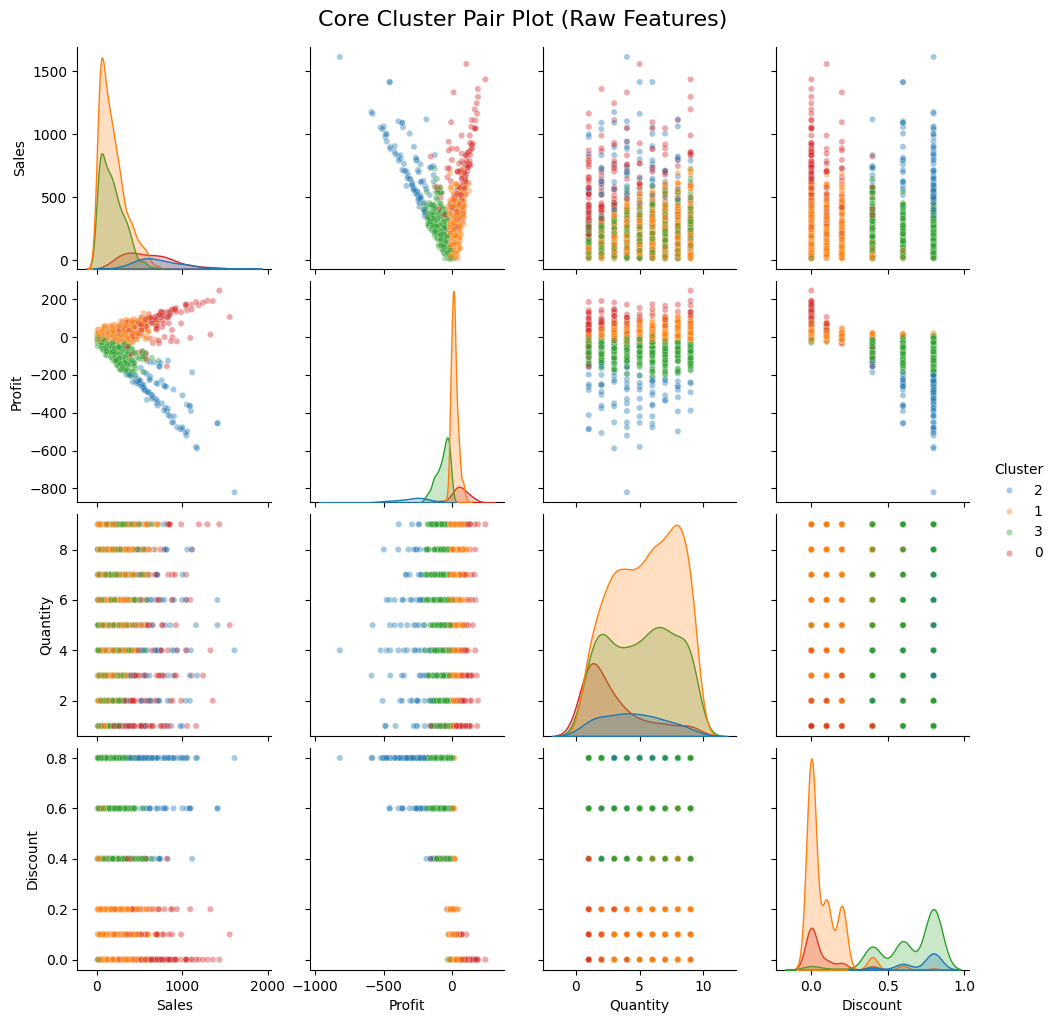

In [20]:
if 'df' in globals():
    sample_df = df.sample(n=min(1500, len(df)), random_state=42)
    # Keep Cluster only as a hue, not as an active x/y variable
    core_vars = ['Sales', 'Profit', 'Quantity', 'Discount']
    g = sns.pairplot(sample_df[core_vars + ['Cluster']], hue='Cluster', palette='tab10',
                     plot_kws={'alpha': 0.4, 's': 20})
    g.fig.suptitle("Core Cluster Pair Plot (Raw Features)", y=1.02, fontsize=16)
    plt.show()
else:
    print("Error: 'df' is not defined. Please run cell b2ddb264 first.")

```markdown
## Subtask 3: Generate the Extended Pair Plot
We substitute `Quantity` with our engineered features to investigate how unit-economics map to our segments.
```

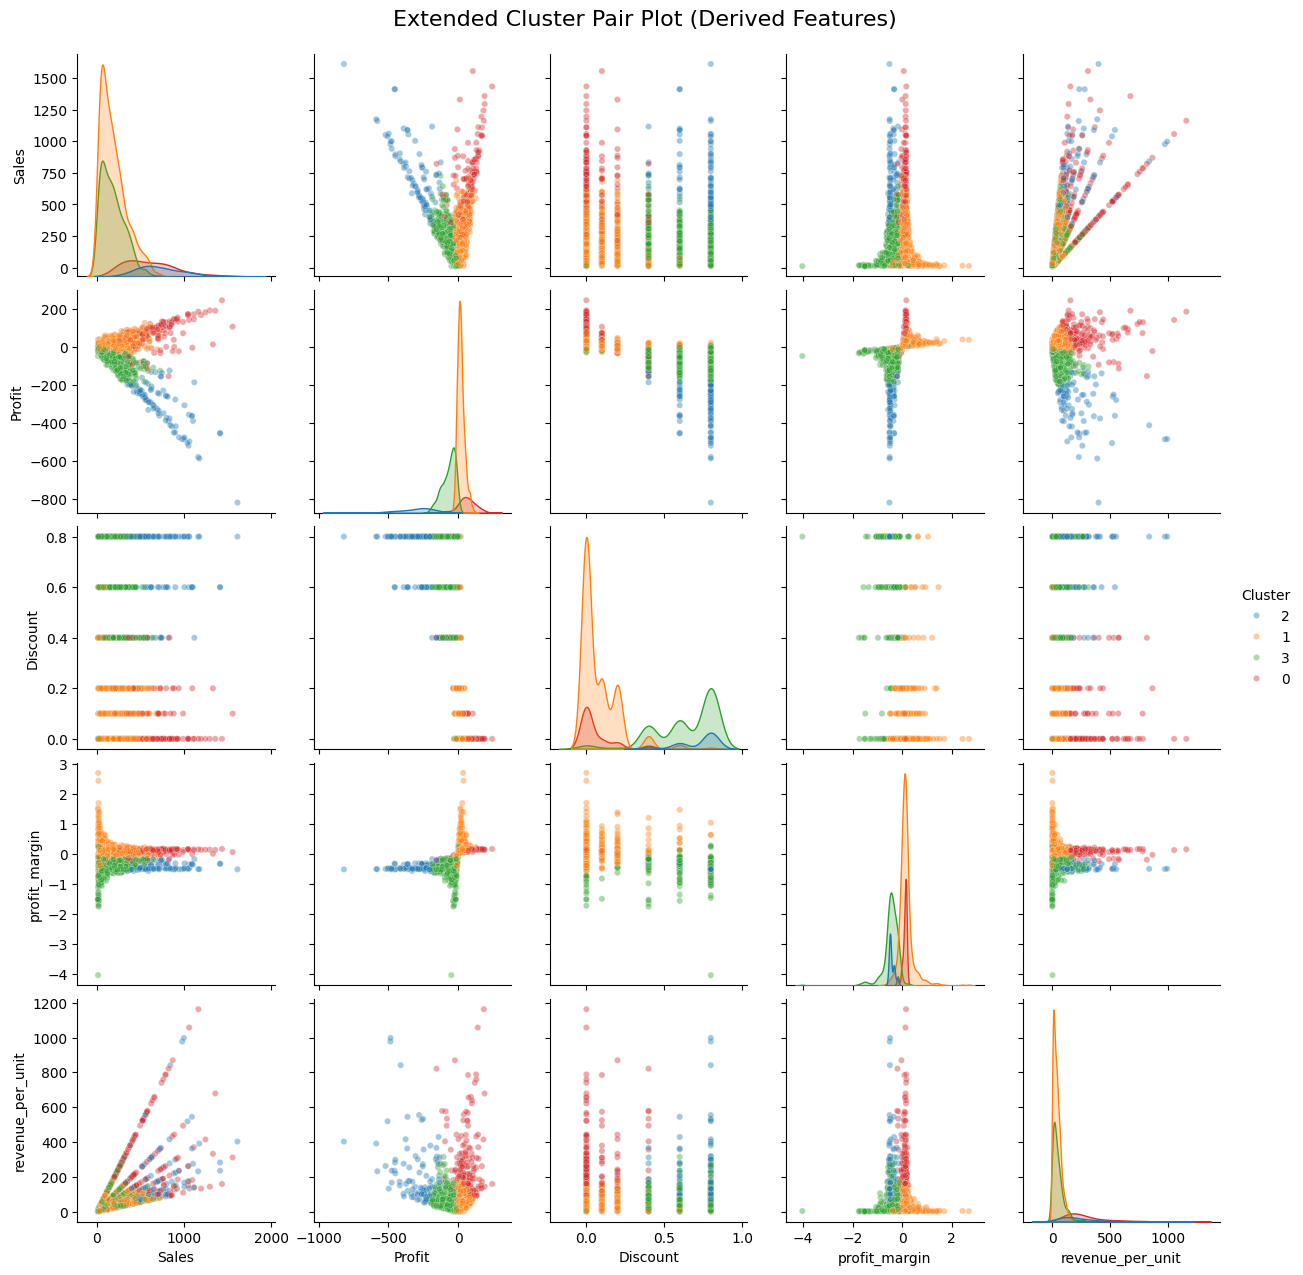

In [21]:
if 'sample_df' in globals():
    extended_vars = ['Sales', 'Profit', 'Discount', 'profit_margin', 'revenue_per_unit']
    g_ext = sns.pairplot(sample_df[extended_vars + ['Cluster']], hue='Cluster', palette='tab10',
                         plot_kws={'alpha': 0.4, 's': 20})
    g_ext.fig.suptitle("Extended Cluster Pair Plot (Derived Features)", y=1.02, fontsize=16)
    plt.show()
else:
    print("Error: 'sample_df' is not defined. Please run cell 2df43e2a first.")

```markdown
## Subtask 4: Build the Full-Dataset Correlation Heatmap
```

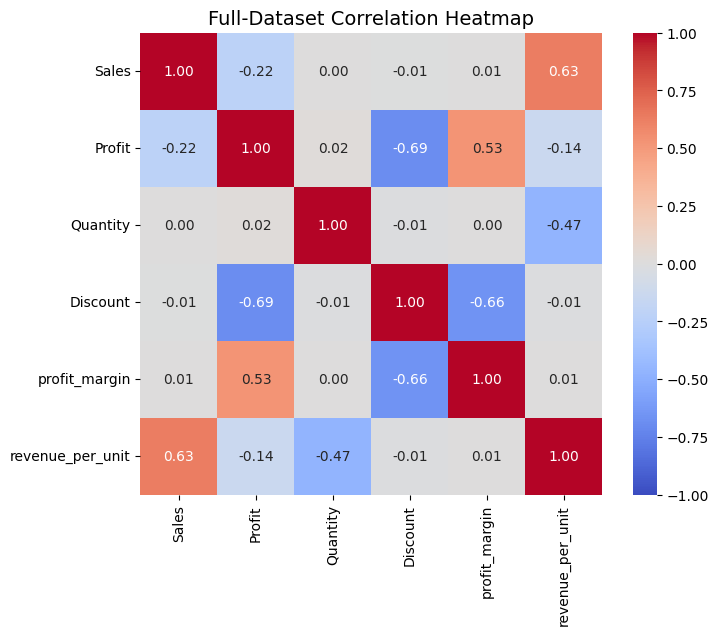

In [14]:
# Ensure df is active and build full-dataset correlation heatmap
if 'df' in globals():
    plt.figure(figsize=(8, 6))
    corr_matrix = df[['Sales', 'Profit', 'Quantity', 'Discount', 'profit_margin', 'revenue_per_unit']].corr()
    sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', vmin=-1, vmax=1, square=True, fmt='.2f')
    plt.title("Full-Dataset Correlation Heatmap", fontsize=14)
    plt.show()
else:
    print("Error: 'df' is not defined. Please run cell b2ddb264 first.")

```markdown
## Subtask 5: Build Per-Cluster Correlation Heatmaps
```

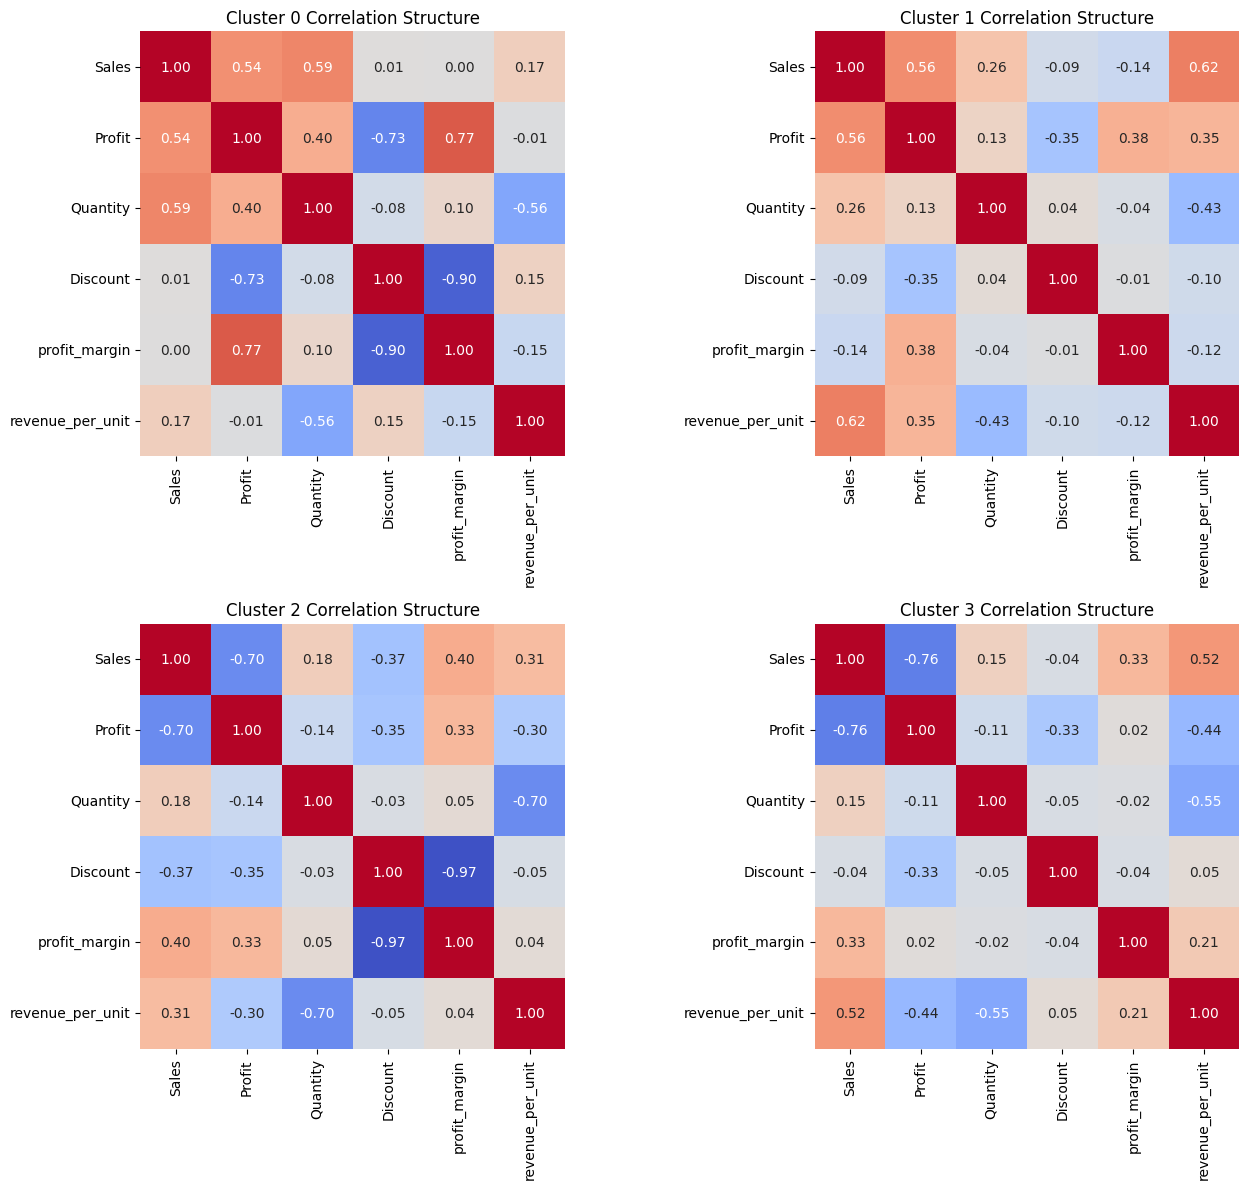

In [15]:
# Ensure df is active and build per-cluster heatmaps
if 'df' in globals():
    clusters = sorted(df['Cluster'].unique())
    fig, axes = plt.subplots(2, 2, figsize=(14, 12))
    axes = axes.flatten()

    for i, cluster in enumerate(clusters):
        cluster_df = df[df['Cluster'] == cluster][['Sales', 'Profit', 'Quantity', 'Discount', 'profit_margin', 'revenue_per_unit']]
        cluster_corr = cluster_df.corr()
        sns.heatmap(cluster_corr, annot=True, cmap='coolwarm', vmin=-1, vmax=1, square=True, fmt='.2f', ax=axes[i], cbar=False)
        axes[i].set_title(f"Cluster {cluster} Correlation Structure", fontsize=12)

    plt.tight_layout()
    plt.show()
else:
    print("Error: 'df' is not defined. Please run cell b2ddb264 first.")

```markdown
## Subtask 6: The Furniture Category Deep Dive
```

In [16]:
# Ensure df is active and extract the Furniture category
if 'df' in globals():
    df_furniture = df[df['Category'] == 'Furniture'].copy()
    print(f"Furniture orders: {len(df_furniture)}")
else:
    print("Error: 'df' is not defined. Please run cell b2ddb264 first.")

Furniture orders: 739


```markdown
### Question 1: Pair Plot for Furniture
```

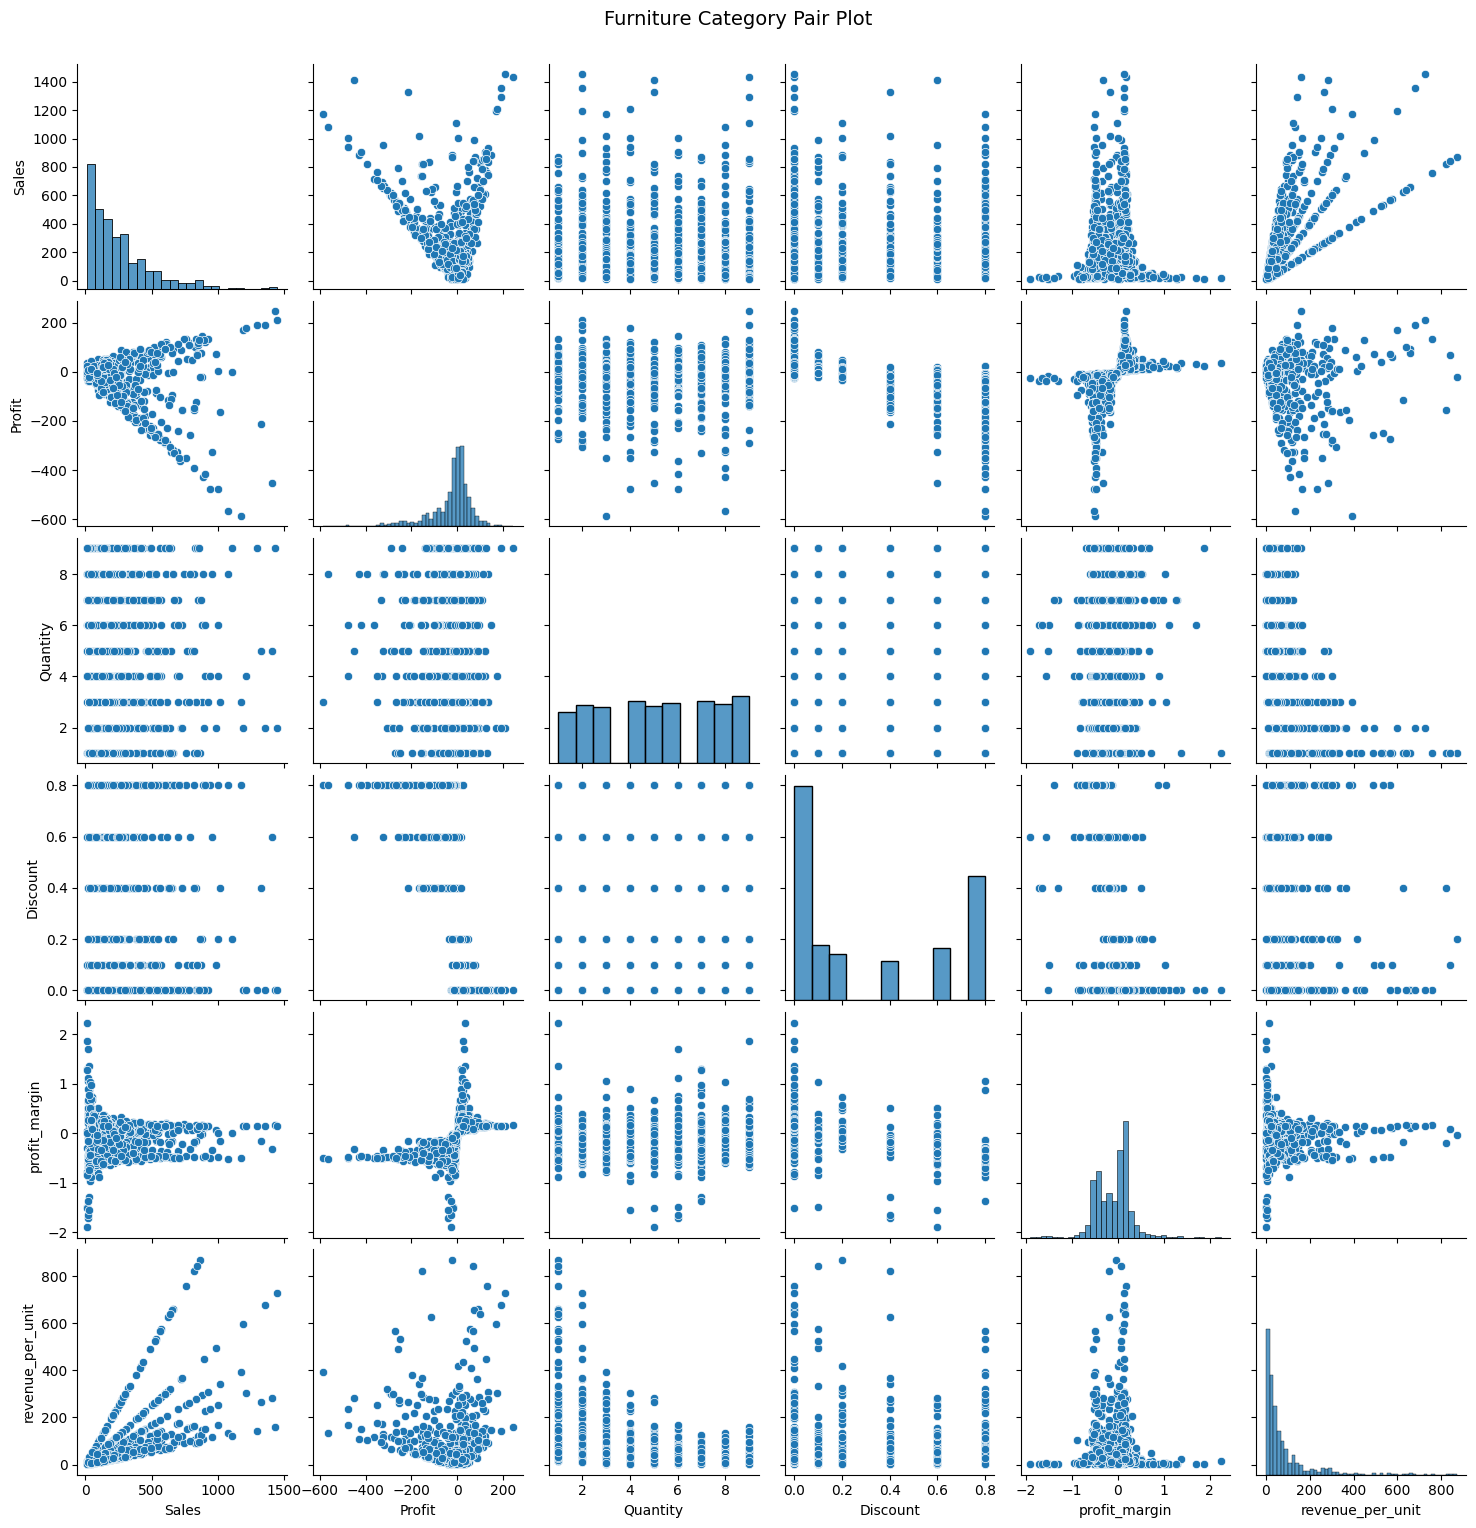

In [17]:
# Ensure df_furniture is present and generate its pair plot
if 'df_furniture' in globals():
    furniture_num = df_furniture[['Sales', 'Profit', 'Quantity', 'Discount', 'profit_margin', 'revenue_per_unit']]
    g_furn = sns.pairplot(furniture_num, corner=False)
    g_furn.fig.suptitle("Furniture Category Pair Plot", y=1.02, fontsize=14)
    plt.show()
else:
    print("Error: 'df_furniture' is not defined. Please run cell 4b1e9062 first.")

```markdown
**Finding:** The profit distribution on the diagonal panel is highly asymmetric, showing a prominent peak near zero with a very long negative tail that indicates severe losses on specific promotional furniture sales.
```

```markdown
### Question 2: Correlation Matrix for Furniture
```

In [18]:
# Ensure df_furniture is present and calculate the correlation matrix
if 'df_furniture' in globals():
    furniture_num = df_furniture[['Sales', 'Profit', 'Quantity', 'Discount', 'profit_margin', 'revenue_per_unit']]
    furn_corr = furniture_num.corr()
    display(furn_corr)
else:
    print("Error: 'df_furniture' is not defined. Please run cell 4b1e9062 first.")

,Sales,Profit,Quantity,Discount,profit_margin,revenue_per_unit
Sales,1.000000,-0.217923,-0.039330,0.024439,-0.016143,0.648496
Profit,-0.217923,1.000000,0.023512,-0.709931,0.544812,-0.085102
Quantity,-0.039330,0.023512,1.000000,-0.045571,0.033872,-0.497057
Discount,0.024439,-0.709931,-0.045571,1.000000,-0.665654,-0.004425
profit_margin,-0.016143,0.544812,0.033872,-0.665654,1.000000,0.000652
revenue_per_unit,0.648496,-0.085102,-0.497057,-0.004425,0.000652,1.000000


**Finding:** In the Furniture segment, the highest correlation exists between `Profit` and `profit_margin` ($r \approx 0.54$) and between `Sales` and `revenue_per_unit` ($r \approx 0.65$). Additionally, the high negative correlation between `Discount` and `Profit` ($r \approx -0.71$) is significantly stronger than in the global dataset ($r \approx -0.69$), proving that promotional discounting disproportionately harms Furniture segment profitability compared to other products.

```markdown
### Question 3: Lower-Triangle Correlation Heatmap for Furniture
```

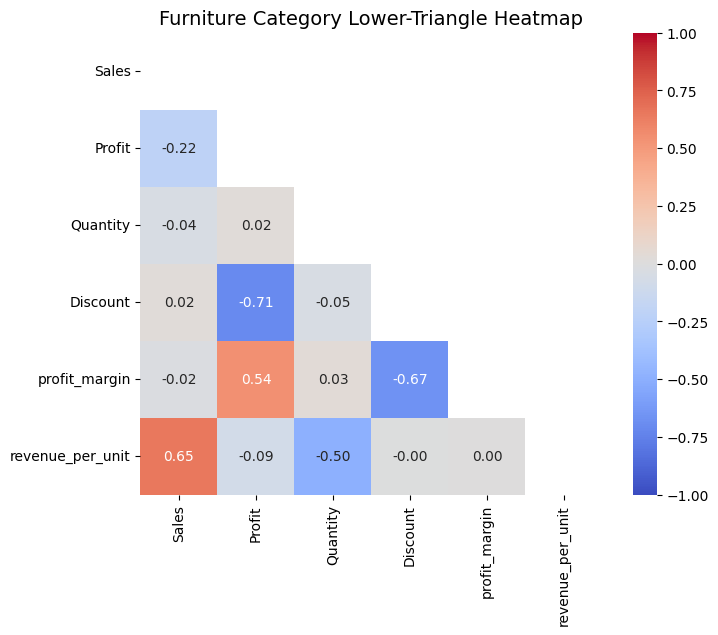

In [19]:
# Ensure furn_corr is present and build lower-triangle heatmap
if 'furn_corr' in globals():
    import numpy as np
    import matplotlib.pyplot as plt
    import seaborn as sns

    mask = np.triu(np.ones_like(furn_corr, dtype=bool))
    plt.figure(figsize=(8, 6))
    sns.heatmap(furn_corr, mask=mask, annot=True, cmap='coolwarm', vmin=-1, vmax=1, square=True, fmt='.2f')
    plt.title("Furniture Category Lower-Triangle Heatmap", fontsize=14)
    plt.show()
else:
    # Fallback definition if the previous block was skipped
    if 'df_furniture' in globals():
        furniture_num = df_furniture[['Sales', 'Profit', 'Quantity', 'Discount', 'profit_margin', 'revenue_per_unit']]
        furn_corr = furniture_num.corr()
        mask = np.triu(np.ones_like(furn_corr, dtype=bool))
        plt.figure(figsize=(8, 6))
        sns.heatmap(furn_corr, mask=mask, annot=True, cmap='coolwarm', vmin=-1, vmax=1, square=True, fmt='.2f')
        plt.title("Furniture Category Lower-Triangle Heatmap", fontsize=14)
        plt.show()
    else:
        print("Error: 'df_furniture' or 'furn_corr' is not defined.")

```markdown
**Finding:** The Discount–Profit cell in the Furniture heatmap displays a deeper cool tone compared to the overall dataset's heatmap, visually demonstrating that discounting strategies are significantly more damaging to margins in the Furniture segment than in the portfolio as a whole.
```